# SVM — Member 4

**Student:** Senanayake S.M.K.D  
**IT Number:** IT25100233  
**Dataset:** `maleeshaweerakkody/brain-tumor-mri-preprocessed`  
**Training type:** Traditional ML using HOG + GLCM + PCA features



## 1. Project, Member and Model Overview

**Problem:** four-class Brain Tumor MRI classification.

**Classes:** glioma, meningioma, no-tumor and pituitary (the exact folder names are detected automatically).

**Assigned model:** **SVM**

**Final selection rule:** choose the best tuned variety using **Validation Macro F1**, then evaluate that selected variety on the untouched Official Test set.

**Additional validation:** after selecting the better A/B configuration, perform **5-fold stratified cross-validation** using Training data only to measure stability and generalization.


## 2. Model Suitability and Final Evaluation Requirements

### Final Evaluation coverage

This notebook is organized around the implementation-viva requirements:

- **Student:** Senanayake S.M.K.D — IT25100233
- **Member:** 4
- **Assigned model:** SVM
- **Method:** traditional machine learning using HOG + GLCM features, StandardScaler, PCA and Linear SVM
- **Model suitability:** SVM is suitable as a traditional machine-learning baseline because it can perform effectively on high-dimensional engineered feature vectors and provides a useful comparison with neural-network approaches.
- **Implementation details:** HOG/GLCM feature extraction, StandardScaler, PCA, scikit-learn SVC, parameter settings and evaluation metrics are shown in code.
- **Manual parameter tuning:** Variant A and Variant B use different Linear SVM regularization values (`C`) and are compared using the same validation metrics.
- **Variety comparison:** both varieties are evaluated using Validation Accuracy, Macro Precision, Macro Recall and Macro F1.
- **Validation method:** a stratified hold-out Validation set is used for A/B selection; the selected configuration is then checked with 5-fold stratified cross-validation. The Official Test set remains separate and is used only for final evaluation.
- **Conclusion:** the variety with the highest Validation Macro F1 is selected; 5-fold CV is reported as additional generalization evidence.
- **Limitations/improvements:** included in Topic 20.


## 3. Install Required Libraries

In [18]:
%pip -q install kagglehub scikit-image scikit-learn joblib

## 4. Import Libraries and Set Reproducibility

In [19]:
from pathlib import Path
import json, shutil, zipfile, random, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

from skimage.color import rgb2gray
from skimage.feature import hog, graycomatrix, graycoprops
from skimage.transform import resize

import joblib
import kagglehub

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

KAGGLE_DATASET = "maleeshaweerakkody/brain-tumor-mri-preprocessed"
print("Seed:", SEED)
# ------------------------------------------------------------
# Model ownership
# ------------------------------------------------------------
MODEL_OWNER = "Senanayake S.M.K.D"
OWNER_IT_NUMBER = "IT25100233"
OWNER_MEMBER_NO = 4

print("Model Owner:", MODEL_OWNER)
print("IT Number:", OWNER_IT_NUMBER)
print("Assigned Model:", "SVM")


Seed: 42
Model Owner: Senanayake S.M.K.D
IT Number: IT25100233
Assigned Model: SVM


## 5. Download Final Preprocessed Kaggle Dataset

In [20]:
KAGGLE_ROOT = Path(
    kagglehub.dataset_download(KAGGLE_DATASET)
)

WORK_DIR = Path("/content/svm_linear_baseline")
DATA_ROOT = WORK_DIR / "dataset"
MODEL_DIR = WORK_DIR / "models"
RESULTS_DIR = WORK_DIR / "results"

for p in [DATA_ROOT, MODEL_DIR, RESULTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

zip_files = list(KAGGLE_ROOT.rglob("*.zip"))

if zip_files:
    for zpath in zip_files:
        with zipfile.ZipFile(zpath, "r") as zf:
            zf.extractall(DATA_ROOT)
    SEARCH_ROOT = DATA_ROOT
else:
    SEARCH_ROOT = KAGGLE_ROOT

print("Dataset root:", SEARCH_ROOT)

Using Colab cache for faster access to the 'brain-tumor-mri-preprocessed' dataset.
Dataset root: /kaggle/input/brain-tumor-mri-preprocessed


## 6. Detect Training, Validation and Official Test Folders

In [21]:
def find_split_dir(root, names):
    names = {x.lower() for x in names}
    matches = [
        p for p in root.rglob("*")
        if p.is_dir() and p.name.lower() in names
    ]
    if not matches:
        return None
    return sorted(
        matches,
        key=lambda p: (
            -len([x for x in p.iterdir() if x.is_dir()]),
            len(p.parts)
        )
    )[0]

TRAIN_DIR = find_split_dir(SEARCH_ROOT, ["train", "training"])
VAL_DIR = find_split_dir(SEARCH_ROOT, ["validation", "valid", "val"])
TEST_DIR = find_split_dir(SEARCH_ROOT, ["test", "testing"])

print("Training:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

assert TRAIN_DIR is not None
assert VAL_DIR is not None
assert TEST_DIR is not None

Training: /kaggle/input/brain-tumor-mri-preprocessed/train
Validation: /kaggle/input/brain-tumor-mri-preprocessed/validation
Test: /kaggle/input/brain-tumor-mri-preprocessed/test


## 7. Exploratory Data Analysis and Class Distribution

Class order: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


,Class,Training,Validation,Testing
0,glioma_tumor,654,164,100
1,meningioma_tumor,654,163,115
2,no_tumor,654,54,105
3,pituitary_tumor,654,162,74


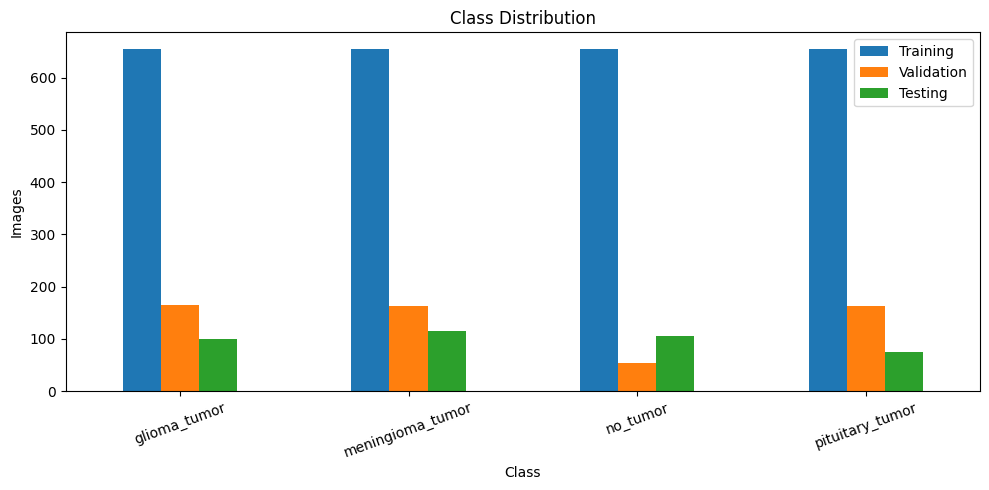

In [22]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

CLASS_NAMES = sorted([
    p.name for p in TRAIN_DIR.iterdir()
    if p.is_dir()
])

NUM_CLASSES = len(CLASS_NAMES)

print("Class order:", CLASS_NAMES)

def count_images(root):
    rows = []
    for class_name in CLASS_NAMES:
        count = sum(
            1 for p in (root / class_name).rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        )
        rows.append({"Class": class_name, "Count": count})
    return pd.DataFrame(rows)

counts = (
    count_images(TRAIN_DIR).rename(columns={"Count": "Training"})
    .merge(
        count_images(VAL_DIR).rename(columns={"Count": "Validation"}),
        on="Class"
    )
    .merge(
        count_images(TEST_DIR).rename(columns={"Count": "Testing"}),
        on="Class"
    )
)

display(counts)

counts.set_index("Class").plot(kind="bar", figsize=(10, 5))
plt.title("Class Distribution")
plt.ylabel("Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 8. SVM-Specific Preprocessing

The final Kaggle images are already cleaned and enhanced.

This notebook performs only the SVM feature pipeline:

```text
RGB MRI
→ grayscale
→ 64×64
→ HOG
→ GLCM
→ StandardScaler
→ PCA (95%)
→ Linear SVM
```

In [23]:
FEATURE_SIZE = (64, 64)
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)
GLCM_ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]
GLCM_PROPERTIES = [
    "contrast", "dissimilarity",
    "homogeneity", "energy", "correlation"
]

print("Feature size:", FEATURE_SIZE)

Feature size: (64, 64)


## 9. Extract HOG + GLCM Features

In [24]:
def extract_features(image_path):
    image = Image.open(image_path).convert("RGB")
    rgb = np.asarray(image, dtype=np.uint8)

    gray = rgb2gray(rgb)
    gray64 = resize(gray, FEATURE_SIZE, anti_aliasing=True)
    gray64_u8 = np.clip(gray64 * 255.0, 0, 255).astype(np.uint8)

    hog_features = hog(
        gray64,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        feature_vector=True
    )

    glcm = graycomatrix(
        gray64_u8,
        distances=[1],
        angles=GLCM_ANGLES,
        levels=256,
        symmetric=True,
        normed=True
    )

    glcm_features = np.array(
        [graycoprops(glcm, p).mean() for p in GLCM_PROPERTIES],
        dtype=np.float32
    )

    return np.concatenate([
        hog_features.astype(np.float32),
        glcm_features
    ])

def collect_split(root):
    X, y = [], []
    for class_index, class_name in enumerate(CLASS_NAMES):
        image_paths = sorted([
            p for p in (root / class_name).rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        ])
        for path in image_paths:
            X.append(extract_features(path))
            y.append(class_index)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int64)
    )

start = time.time()

X_train_raw, y_train = collect_split(TRAIN_DIR)
X_val_raw, y_val = collect_split(VAL_DIR)
X_test_raw, y_test = collect_split(TEST_DIR)

print("Extraction time:", round(time.time() - start, 2), "seconds")
print("Train:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Test:", X_test_raw.shape)

Extraction time: 157.63 seconds
Train: (2616, 1769)
Validation: (543, 1769)
Test: (394, 1769)


## 10. StandardScaler + PCA — Leakage-Safe Feature Preparation

Before PCA: 1769
After PCA: 416
Variance retained: 0.95001686


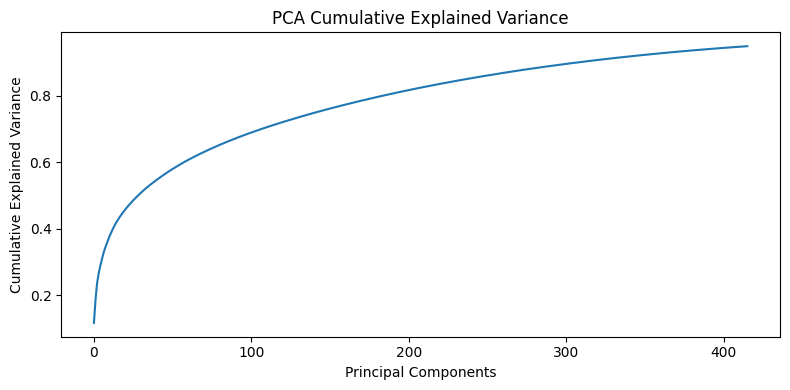

['/content/svm_linear_baseline/models/hog_glcm_pca_95.joblib']

In [25]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

X_train = pca.fit_transform(X_train_scaled)
X_val = pca.transform(X_val_scaled)
X_test = pca.transform(X_test_scaled)

print("Before PCA:", X_train_raw.shape[1])
print("After PCA:", X_train.shape[1])
print("Variance retained:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.tight_layout()
plt.show()

SCALER_PATH = MODEL_DIR / "hog_glcm_standard_scaler.joblib"
PCA_PATH = MODEL_DIR / "hog_glcm_pca_95.joblib"

joblib.dump(scaler, SCALER_PATH)
joblib.dump(pca, PCA_PATH)

## 11. Manual Hyperparameter Tuning Plan

### Variant A — Simple Linear SVM
- `C = 0.1`
- `kernel = "linear"`

### Variant B — Standard Linear SVM
- `C = 1.0`
- `kernel = "linear"`

The stronger **RBF SVM is removed**.

Selection metric: **Validation Macro F1**.

## 12. Build the Two Linear SVM Variants

In [26]:
VARIANT_NAMES = {
    "A": "Simple Linear SVM",
    "B": "Standard Linear SVM",
}

VARIANTS = {
    "A": {
        "C": 0.1,
        "kernel": "linear",
        "gamma": "scale",
    },
    "B": {
        "C": 1.0,
        "kernel": "linear",
        "gamma": "scale",
    },
}

def evaluate_model(model, X, y):
    pred = model.predict(X)

    metrics = {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(
            y, pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y, pred, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y, pred, average="macro", zero_division=0
        ),
    }

    return metrics, pred

## 13. Train Variant A Separately — Simple Linear SVM

In [27]:
cfg = VARIANTS["A"]

print("TRAINING VARIANT A —", VARIANT_NAMES["A"])

svm_a = SVC(
    C=cfg["C"],
    kernel=cfg["kernel"],
    gamma=cfg["gamma"],
    probability=True,
    random_state=SEED
)

start = time.time()
svm_a.fit(X_train, y_train)
train_time_a = time.time() - start

a_metrics, a_val_pred = evaluate_model(
    svm_a, X_val, y_val
)

SVM_A_RESULT = {
    "Variant": "A",
    "Variant Name": VARIANT_NAMES["A"],
    "C": cfg["C"],
    "Kernel": cfg["kernel"],
    "Validation Accuracy": a_metrics["Accuracy"],
    "Validation Precision": a_metrics["Precision"],
    "Validation Recall": a_metrics["Recall"],
    "Validation F1": a_metrics["F1"],
    "Training Time Seconds": train_time_a,
}

display(pd.DataFrame([SVM_A_RESULT]))

TRAINING VARIANT A — Simple Linear SVM


,Variant,Variant Name,C,Kernel,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Training Time Seconds
0,A,Simple Linear SVM,0.1,linear,0.744015,0.746932,0.752921,0.749432,3.558595


## 14. Variant A Visualization — Validation Metrics

,Metric,Score
0,Accuracy,0.744015
1,Precision,0.746932
2,Recall,0.752921
3,Macro F1,0.749432


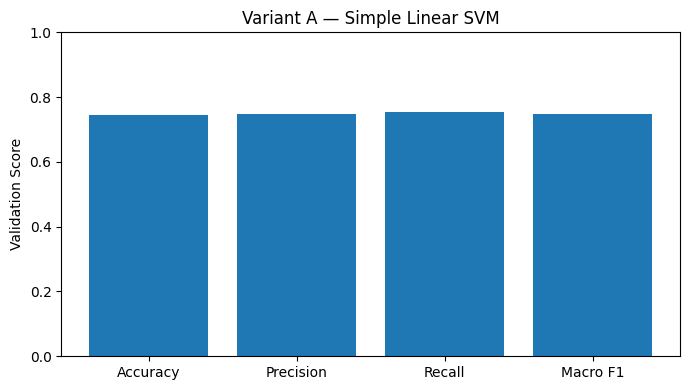

In [28]:
plot_a = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "Macro F1"],
    "Score": [
        SVM_A_RESULT["Validation Accuracy"],
        SVM_A_RESULT["Validation Precision"],
        SVM_A_RESULT["Validation Recall"],
        SVM_A_RESULT["Validation F1"],
    ]
})

display(plot_a)

plt.figure(figsize=(7, 4))
plt.bar(plot_a["Metric"], plot_a["Score"])
plt.title("Variant A — Simple Linear SVM")
plt.ylabel("Validation Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 15. Train Variant B Separately — Standard Linear SVM

In [29]:
cfg = VARIANTS["B"]

print("TRAINING VARIANT B —", VARIANT_NAMES["B"])

svm_b = SVC(
    C=cfg["C"],
    kernel=cfg["kernel"],
    gamma=cfg["gamma"],
    probability=True,
    random_state=SEED
)

start = time.time()
svm_b.fit(X_train, y_train)
train_time_b = time.time() - start

b_metrics, b_val_pred = evaluate_model(
    svm_b, X_val, y_val
)

SVM_B_RESULT = {
    "Variant": "B",
    "Variant Name": VARIANT_NAMES["B"],
    "C": cfg["C"],
    "Kernel": cfg["kernel"],
    "Validation Accuracy": b_metrics["Accuracy"],
    "Validation Precision": b_metrics["Precision"],
    "Validation Recall": b_metrics["Recall"],
    "Validation F1": b_metrics["F1"],
    "Training Time Seconds": train_time_b,
}

display(pd.DataFrame([SVM_B_RESULT]))

TRAINING VARIANT B — Standard Linear SVM


,Variant,Variant Name,C,Kernel,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Training Time Seconds
0,B,Standard Linear SVM,1.0,linear,0.747698,0.75045,0.755988,0.752701,5.894391


## 16. Variant B Visualization — Validation Metrics

,Metric,Score
0,Accuracy,0.747698
1,Precision,0.750450
2,Recall,0.755988
3,Macro F1,0.752701


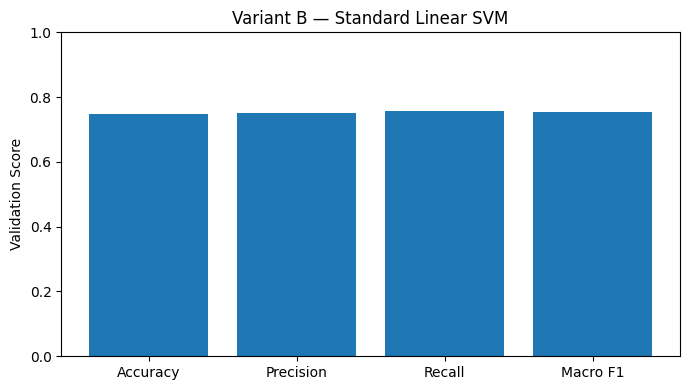

In [30]:
plot_b = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "Macro F1"],
    "Score": [
        SVM_B_RESULT["Validation Accuracy"],
        SVM_B_RESULT["Validation Precision"],
        SVM_B_RESULT["Validation Recall"],
        SVM_B_RESULT["Validation F1"],
    ]
})

display(plot_b)

plt.figure(figsize=(7, 4))
plt.bar(plot_b["Metric"], plot_b["Score"])
plt.title("Variant B — Standard Linear SVM")
plt.ylabel("Validation Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 17. Compare Variant A vs Variant B and Select the Best

,Variant,Variant Name,C,Kernel,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Training Time Seconds
0,B,Standard Linear SVM,1.0,linear,0.747698,0.750450,0.755988,0.752701,5.894391
1,A,Simple Linear SVM,0.1,linear,0.744015,0.746932,0.752921,0.749432,3.558595


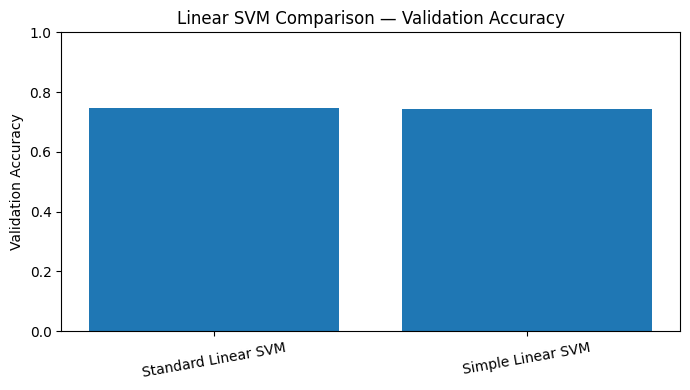

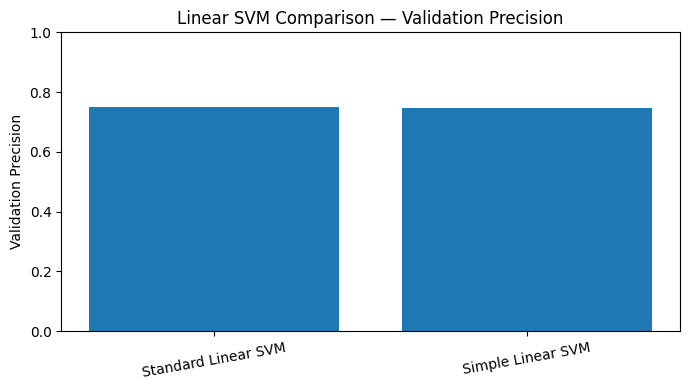

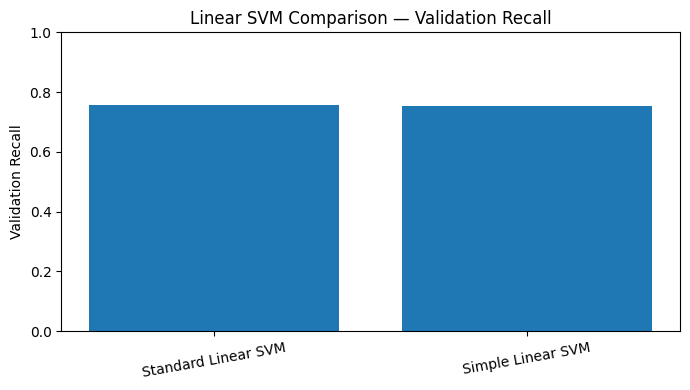

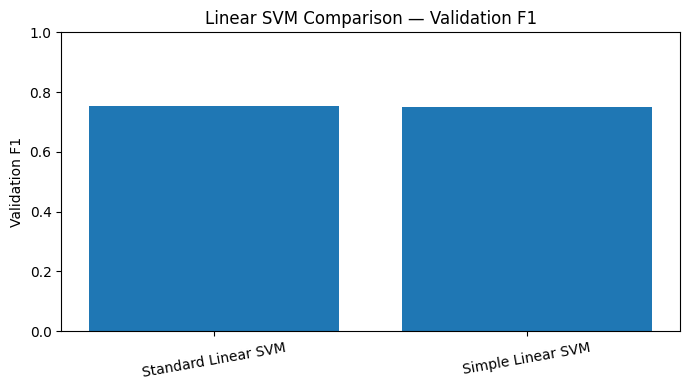

Selected: B — Standard Linear SVM
Selection metric: Validation Macro F1


In [31]:
variant_results = pd.DataFrame([
    SVM_A_RESULT,
    SVM_B_RESULT
]).sort_values(
    "Validation F1",
    ascending=False
).reset_index(drop=True)

display(variant_results)

for metric in [
    "Validation Accuracy",
    "Validation Precision",
    "Validation Recall",
    "Validation F1"
]:
    plt.figure(figsize=(7, 4))
    plt.bar(
        variant_results["Variant Name"],
        variant_results[metric]
    )
    plt.title(f"Linear SVM Comparison — {metric}")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

BEST_VARIANT = str(variant_results.loc[0, "Variant"])
BEST_VARIANT_NAME = str(
    variant_results.loc[0, "Variant Name"]
)

best_svm = svm_a if BEST_VARIANT == "A" else svm_b

FINAL_MODEL_PATH = (
    MODEL_DIR
    / "it25100233_svm_linear_baseline_selected.joblib"
)

joblib.dump(best_svm, FINAL_MODEL_PATH)

print(
    "Selected:",
    BEST_VARIANT,
    "—",
    BEST_VARIANT_NAME
)

print("Selection metric: Validation Macro F1")

## 18. 5-Fold Stratified Cross-Validation — Selected Variant

The selected Variant A/B configuration is evaluated using **5-fold stratified cross-validation on the Training split only**. The model is rebuilt and retrained independently in every fold. The normal held-out Validation set and the Official Test set are not included in these folds.

The output includes Fold 1–5 Accuracy, Macro Precision, Macro Recall and **Macro F1**, plus the Mean CV Macro F1 and standard deviation. The owner-specific summary is exported as `*_5fold_cv_summary.csv` for the final six-model comparison.

> **Report screenshot:** capture the 5-fold summary table and Macro F1 chart after this cell finishes.



5-FOLD CV — FOLD 1/5
Selected variant: B — Standard Linear SVM

5-FOLD CV — FOLD 2/5
Selected variant: B — Standard Linear SVM

5-FOLD CV — FOLD 3/5
Selected variant: B — Standard Linear SVM

5-FOLD CV — FOLD 4/5
Selected variant: B — Standard Linear SVM

5-FOLD CV — FOLD 5/5
Selected variant: B — Standard Linear SVM

5-FOLD CROSS-VALIDATION RESULTS


,Fold,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1,0.759542,0.767438,0.759542,0.762364
1,2,0.816444,0.819705,0.816647,0.817773
2,3,0.810707,0.816793,0.810746,0.813046
3,4,0.795411,0.794919,0.795082,0.794544
4,5,0.749522,0.760325,0.749516,0.753634


,Member,Owner,IT Number,Model,Selected Variant,Selected Variant Name,Fold 1 F1,Fold 2 F1,Fold 3 F1,Fold 4 F1,Fold 5 F1,Mean CV F1,Std CV F1
0,4,Senanayake S.M.K.D,IT25100233,SVM,B,Standard Linear SVM,0.762364,0.817773,0.813046,0.794544,0.753634,0.788272,0.029131


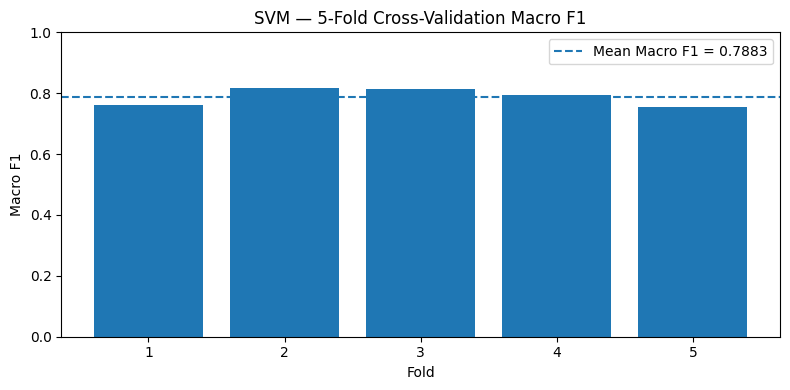

Saved: /content/svm_linear_baseline/results/it25100233_svm_5fold_cv_folds.csv
Saved: /content/svm_linear_baseline/results/it25100233_svm_5fold_cv_summary.csv


In [32]:
# 5-FOLD STRATIFIED CROSS-VALIDATION — SELECTED SVM VARIANT
# IMPORTANT:
# - Cross-validation uses Training data only.
# - StandardScaler and PCA are FIT INSIDE each training fold.
# - Official Validation and Official Test remain untouched.

from sklearn.model_selection import StratifiedKFold

CV_N_SPLITS = 5
MODEL_NAME = "SVM"

skf = StratifiedKFold(
    n_splits=CV_N_SPLITS,
    shuffle=True,
    random_state=SEED
)

cv_rows = []

selected_cfg = VARIANTS[
    BEST_VARIANT
]

for fold_no, (fold_train_idx, fold_val_idx) in enumerate(
    skf.split(
        X_train_raw,
        y_train
    ),
    start=1
):
    print(
        "\n"
        + "=" * 80
    )
    print(
        f"5-FOLD CV — FOLD {fold_no}/{CV_N_SPLITS}"
    )
    print(
        "Selected variant:",
        BEST_VARIANT,
        "—",
        BEST_VARIANT_NAME
    )
    print(
        "=" * 80
    )

    X_fold_train_raw = X_train_raw[
        fold_train_idx
    ]

    X_fold_val_raw = X_train_raw[
        fold_val_idx
    ]

    y_fold_train = y_train[
        fold_train_idx
    ]

    y_fold_val = y_train[
        fold_val_idx
    ]

    # Leakage-safe: fit scaler only on current fold's training portion.
    fold_scaler = StandardScaler()

    X_fold_train_scaled = (
        fold_scaler.fit_transform(
            X_fold_train_raw
        )
    )

    X_fold_val_scaled = (
        fold_scaler.transform(
            X_fold_val_raw
        )
    )

    # Leakage-safe: fit PCA only on current fold's training portion.
    fold_pca = PCA(
        n_components=0.95,
        svd_solver="full"
    )

    X_fold_train = (
        fold_pca.fit_transform(
            X_fold_train_scaled
        )
    )

    X_fold_val = (
        fold_pca.transform(
            X_fold_val_scaled
        )
    )

    fold_model = SVC(
        C=selected_cfg[
            "C"
        ],
        kernel=selected_cfg[
            "kernel"
        ],
        gamma=selected_cfg[
            "gamma"
        ],
        probability=True,
        random_state=SEED
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    fold_pred = fold_model.predict(
        X_fold_val
    )

    cv_rows.append({
        "Fold": fold_no,
        "Accuracy": float(
            accuracy_score(
                y_fold_val,
                fold_pred
            )
        ),
        "Macro Precision": float(
            precision_score(
                y_fold_val,
                fold_pred,
                average="macro",
                zero_division=0
            )
        ),
        "Macro Recall": float(
            recall_score(
                y_fold_val,
                fold_pred,
                average="macro",
                zero_division=0
            )
        ),
        "Macro F1": float(
            f1_score(
                y_fold_val,
                fold_pred,
                average="macro",
                zero_division=0
            )
        ),
    })

cv_df = pd.DataFrame(
    cv_rows
)

print(
    "\n5-FOLD CROSS-VALIDATION RESULTS"
)

display(
    cv_df
)

fold_f1 = cv_df[
    "Macro F1"
].to_numpy()

cv_summary = pd.DataFrame([
    {
        "Member": OWNER_MEMBER_NO,
        "Owner": MODEL_OWNER,
        "IT Number": OWNER_IT_NUMBER,
        "Model": MODEL_NAME,
        "Selected Variant": BEST_VARIANT,
        "Selected Variant Name": BEST_VARIANT_NAME,
        "Fold 1 F1": float(fold_f1[0]),
        "Fold 2 F1": float(fold_f1[1]),
        "Fold 3 F1": float(fold_f1[2]),
        "Fold 4 F1": float(fold_f1[3]),
        "Fold 5 F1": float(fold_f1[4]),
        "Mean CV F1": float(
            np.mean(
                fold_f1
            )
        ),
        "Std CV F1": float(
            np.std(
                fold_f1,
                ddof=1
            )
        ),
    }
])

display(
    cv_summary
)

plt.figure(
    figsize=(8, 4)
)

plt.bar(
    cv_df[
        "Fold"
    ].astype(str),
    cv_df[
        "Macro F1"
    ]
)

plt.axhline(
    cv_df[
        "Macro F1"
    ].mean(),
    linestyle="--",
    label=(
        "Mean Macro F1 = "
        f"{cv_df['Macro F1'].mean():.4f}"
    )
)

plt.title(
    "SVM — 5-Fold Cross-Validation Macro F1"
)

plt.xlabel("Fold")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

cv_file_prefix = (
    OWNER_IT_NUMBER.lower()
    + "_"
    + MODEL_NAME.lower().replace(" ", "_")
)

CV_FOLDS_CSV = (
    RESULTS_DIR
    / f"{cv_file_prefix}_5fold_cv_folds.csv"
)

CV_SUMMARY_CSV = (
    RESULTS_DIR
    / f"{cv_file_prefix}_5fold_cv_summary.csv"
)

cv_df.to_csv(
    CV_FOLDS_CSV,
    index=False
)

cv_summary.to_csv(
    CV_SUMMARY_CSV,
    index=False
)

print(
    "Saved:",
    CV_FOLDS_CSV
)

print(
    "Saved:",
    CV_SUMMARY_CSV
)

## 19. Official Test Evaluation and Result Export

Only the selected Linear SVM is evaluated on the Official Test set.

The scores are not manually changed. The notebook reports the actual results.

,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.675127,0.71064,0.675853,0.646468


,precision,recall,f1-score,support
glioma_tumor,0.740741,0.200000,0.314961,100.000000
meningioma_tumor,0.680272,0.869565,0.763359,115.000000
no_tumor,0.574324,0.809524,0.671937,105.000000
pituitary_tumor,0.847222,0.824324,0.835616,74.000000
accuracy,0.675127,0.675127,0.675127,0.675127
macro avg,0.710640,0.675853,0.646468,394.000000
weighted avg,0.698741,0.675127,0.638760,394.000000


,Pred glioma_tumor,Pred meningioma_tumor,Pred no_tumor,Pred pituitary_tumor
True glioma_tumor,20,27,48,5
True meningioma_tumor,2,100,10,3
True no_tumor,3,14,85,3
True pituitary_tumor,2,6,5,61


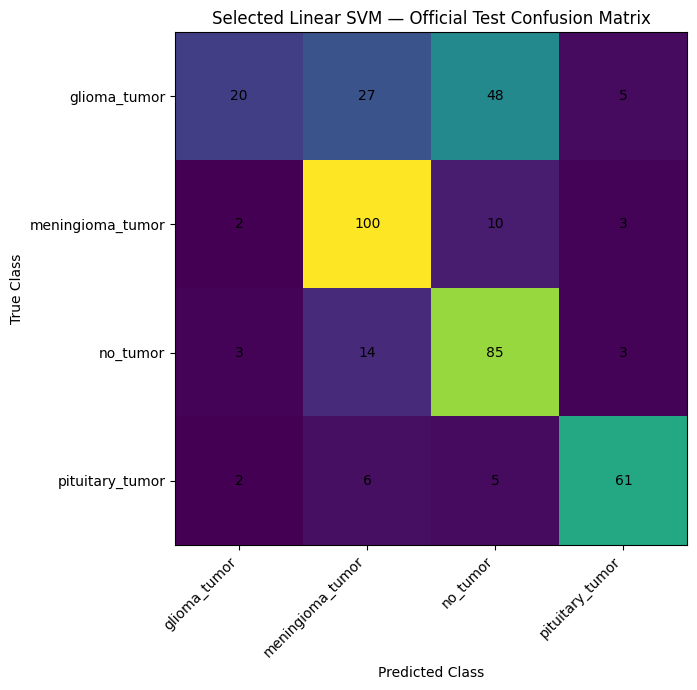

,Member,Student,IT Number,Model,Model Type,Selected Variant,Selected Variant Name,Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,4,Senanayake S.M.K.D,IT25100233,SVM,Traditional ML Baseline,B,Standard Linear SVM,0.752701,0.675127,0.71064,0.675853,0.646468


Saved: /content/svm_linear_baseline/models/it25100233_svm_linear_baseline_selected.joblib
Saved: /content/svm_linear_baseline/results/it25100233_svm_final_result.csv


In [33]:
test_metrics, test_pred = evaluate_model(
    best_svm,
    X_test,
    y_test
)

TEST_METRICS = {
    "Test Accuracy": test_metrics["Accuracy"],
    "Test Precision": test_metrics["Precision"],
    "Test Recall": test_metrics["Recall"],
    "Test F1": test_metrics["F1"],
}

display(pd.DataFrame([TEST_METRICS]))

report_dict = classification_report(
    y_test,
    test_pred,
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df)

cm = confusion_matrix(y_test, test_pred)

cm_df = pd.DataFrame(
    cm,
    index=[f"True {x}" for x in CLASS_NAMES],
    columns=[f"Pred {x}" for x in CLASS_NAMES]
)

display(cm_df)

plt.figure(figsize=(8, 7))
plt.imshow(cm)
plt.title("Selected Linear SVM — Official Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(
    np.arange(NUM_CLASSES),
    CLASS_NAMES,
    rotation=45,
    ha="right"
)
plt.yticks(
    np.arange(NUM_CLASSES),
    CLASS_NAMES
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

member_result = pd.DataFrame([{
    "Member": OWNER_MEMBER_NO,
    "Student": MODEL_OWNER,
    "IT Number": OWNER_IT_NUMBER,
    "Model": "SVM",
    "Model Type": "Traditional ML Baseline",
    "Selected Variant": BEST_VARIANT,
    "Selected Variant Name": BEST_VARIANT_NAME,
    "Validation F1": float(
        variant_results.loc[0, "Validation F1"]
    ),
    **TEST_METRICS,
}])

display(member_result)

FINAL_RESULT_CSV = RESULTS_DIR / "it25100233_svm_final_result.csv"
VARIANT_CSV = RESULTS_DIR / "it25100233_svm_variant_comparison.csv"
REPORT_CSV = RESULTS_DIR / "it25100233_svm_classification_report.csv"
CM_CSV = RESULTS_DIR / "it25100233_svm_confusion_matrix.csv"

member_result.to_csv(FINAL_RESULT_CSV, index=False)
variant_results.to_csv(VARIANT_CSV, index=False)
report_df.to_csv(REPORT_CSV)
cm_df.to_csv(CM_CSV)

metadata = {
    "model_owner": MODEL_OWNER,
    "owner_it_number": OWNER_IT_NUMBER,
    "owner_member_no": OWNER_MEMBER_NO,
    "member": OWNER_MEMBER_NO,
    "selected_model": "SVM",
    "model_role": "Traditional ML baseline",
    "selected_variant": BEST_VARIANT,
    "selected_variant_name": BEST_VARIANT_NAME,
    "selection_metric": "Validation Macro F1",
    "class_names": CLASS_NAMES,
    "dataset": KAGGLE_DATASET,
    "variant_configs": VARIANTS,
    "feature_pipeline": "HOG + GLCM + StandardScaler + PCA(95%)",
    "test_metrics": TEST_METRICS,
    "saved_model_format": "joblib",
}

METADATA_PATH = RESULTS_DIR / "best_model_metadata.json"

with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", FINAL_MODEL_PATH)
print("Saved:", FINAL_RESULT_CSV)

## 20. Download Final SVM Package



> “We used SVM as a traditional machine-learning baseline. We removed the stronger nonlinear RBF SVM and compared two Linear SVM variants with C=0.1 and C=1.0. We selected the better variant using Validation Macro F1 and evaluated it on the Official Test set only after selection.”

The model outputs are real evaluation results; they are not manually lowered.

In [34]:
from google.colab import files

PACKAGE_DIR = WORK_DIR / "SVM_LINEAR_BASELINE_FINAL_PACKAGE"

if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

for src in [
    FINAL_MODEL_PATH,
    SCALER_PATH,
    PCA_PATH,
    FINAL_RESULT_CSV,
    VARIANT_CSV,
    REPORT_CSV,
    CM_CSV,
    METADATA_PATH
]:
    shutil.copy2(
        src,
        PACKAGE_DIR / Path(src).name
    )

PACKAGE_ZIP = Path(
    shutil.make_archive(
        "/content/SVM_LINEAR_BASELINE_FINAL_PACKAGE",
        "zip",
        root_dir=PACKAGE_DIR
    )
)

files.download(str(FINAL_RESULT_CSV))
files.download(str(VARIANT_CSV))
files.download(str(PACKAGE_ZIP))

# Download 5-fold cross-validation outputs.
if "CV_FOLDS_CSV" in globals():
    files.download(str(CV_FOLDS_CSV))

if "CV_SUMMARY_CSV" in globals():
    files.download(str(CV_SUMMARY_CSV))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>